# iSTAR EEG — Cognitive Macrostate Pipeline (single notebook)

This notebook gathers the **whole pipeline** in one place for readability, with
inline graphs. It **calls the existing code in `src/`** (no copy-paste — fix a
`src/*.py` once and the notebook picks it up automatically).

**Structure**
1. **Layer 1** — load EEG -> filter -> STFT -> RSP (theta/alpha/beta) -> K-medoids -> **SRI**
2. **Spectral power** (Deliverable #1) — mean band power per cognitive state
3. **Layer 2** — predict correct/incorrect answering (9 per-question logistic, eqs. 8-9) + cross-validation
4. **Experiment 1** — upgrade the classifier to **SVM-RBF**
5. **Experiment 2** — switch the band-pass filter to **4th-order** (per the thesis)
6. **Summary**

> Note: the Layer-1 cells load the `.mat` files of 22 subjects x 9 questions, so
> they take a few minutes. This notebook runs Layer-1 **twice** (the baseline
> order=3 and the order=4 experiment), so the full run is ~2-5 minutes.

## 0. Setup — point to `src/` and import the existing modules

In [1]:
import sys
from pathlib import Path

# the notebook lives in notebooks/ ; add src/ to sys.path to import the modules
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# existing modules from src/ (no duplicated code)
import config
import macrostates as M
from labels import load_labels
from classify import _per_question, STATES

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

pd.set_option("display.width", 120)
print("config.FILTER_ORDER =", config.FILTER_ORDER, "(Butterworth order)")
print("STATES =", STATES)
print("src in use:", ROOT / "src")

config.FILTER_ORDER = 3 (Butterworth order)
STATES = ['Reading', 'Reasoning', 'Decision']
src in use: /Users/kritsakorn/Documents/intershipProject/src


## 1. Layer 1 — from raw signal to RSP features

**Steps** (in `src/features.py`):
- `load_question_eeg` : load the cognitive segments of a question, concatenate
  them -> band-pass 1-30 Hz Butterworth + 60 Hz notch
- `rsp_features` : STFT (2 s window, 0.1 s step) -> **Relative Spectral Power**
  of theta/alpha/beta per channel -> 33-dim vector per frame (11 channels x 3 bands)
- frames whose 2 s window exceeds +/-150 uV are **dropped** (paper artifact rejection)

Look at one subject / one question first:

In [2]:
from features import load_question_eeg, rsp_features

eeg = load_question_eeg("S1", 2)          # (samples, 19)
feats = rsp_features(eeg)                  # (frames, 33)
print(f"S1 Q2: raw EEG {eeg.shape} (samples x 19 channels)")
print(f"       RSP features {feats.shape} (frames x 33)")
# each channel's theta+alpha+beta must sum to ~1.0 (a proportion)
sums = feats.reshape(feats.shape[0], 11, 3).sum(axis=2)
print(f"       per-channel RSP sum: {sums.min():.4f}..{sums.max():.4f} (expect ~1.0)")

S1 Q2: raw EEG (18918, 19) (samples x 19 channels)
       RSP features (151, 33) (frames x 33)
       per-channel RSP sum: 1.0000..1.0000 (expect ~1.0)


## 2. Layer 1 — K-medoids -> 3 cognitive states -> SRI

`macrostates.cluster_frames()` pools the frames of every subject/question, then
clusters with **K-medoids (K=3, 10 restarts, seed=0)** -> names the states by
frontal-theta order (Reading < Decision < Reasoning) -> computes the **SRI** =
the proportion of time spent in each state per (subject, question).

> Run with `config.FILTER_ORDER = 3` (the baseline); the result should match the
> committed `outputs/tables/sri.csv` (fixed seed).

In [3]:
assert config.FILTER_ORDER == 3, "this cell is the order=3 baseline"
X3, groups3, labels3, names3 = M.cluster_frames()
sri3 = M.compute_sri(labels3, groups3, names3)
print("\nSRI (first 5 rows):")
print(sri3.head().to_string(index=False))

complete subjects (Q1-Q9, files): 27
still complete after artifact rejection: 22
dropped (a question emptied by rejection): ['S2', 'S16', 'S18', 'S25', 'S27']
  ['S1', 'S3', 'S4', 'S5', 'S6', 'S7', 'S10', 'S11', 'S12', 'S13', 'S14', 'S19', 'S22', 'S24', 'S26', 'S28', 'S29', 'S30', 'S31', 'S34', 'S37', 'S38']
feature matrix: (50065, 33)  frames=50065
cluster -> state: {1: 'Reading', 2: 'Decision', 0: 'Reasoning'}

SRI (first 5 rows):
subject  q  Reading  Reasoning  Decision
     S1  1 0.194737   0.471053  0.334211
     S1  2 0.304636   0.470199  0.225166
     S1  3 0.344086   0.419355  0.236559
     S1  4 0.282828   0.353535  0.363636
     S1  5 0.331967   0.442623  0.225410


### Graph: SRI distribution per state

/var/folders/6k/jk203yvs711brq8r7xz737rw0000gn/T/ipykernel_19076/3704966545.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([sri3[s] for s in STATES], labels=STATES, showmeans=True)


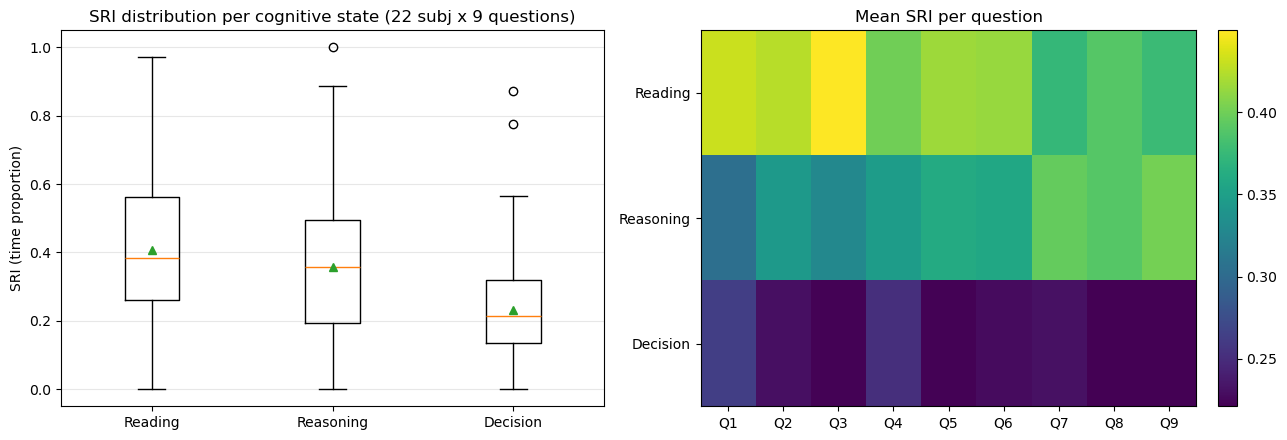

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) boxplot of the SRI distribution of the 3 states across all rows
axes[0].boxplot([sri3[s] for s in STATES], labels=STATES, showmeans=True)
axes[0].set_ylabel("SRI (time proportion)")
axes[0].set_title("SRI distribution per cognitive state (22 subj x 9 questions)")
axes[0].grid(axis="y", alpha=0.3)

# (b) heatmap of the mean SRI per question
pivot = sri3.groupby("q")[STATES].mean()
im = axes[1].imshow(pivot.T.values, aspect="auto", cmap="viridis")
axes[1].set_xticks(range(len(pivot)))
axes[1].set_xticklabels([f"Q{q}" for q in pivot.index])
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(STATES)
axes[1].set_title("Mean SRI per question")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

### Graph: do the 3 macrostates actually separate? (cluster validity)

The whole pipeline hinges on K-medoids finding **3 real cognitive states** in the
33-dim RSP cloud. This graph checks whether those clusters are actually separated.
Reusing the committed partition from section 2 (`X3`, `labels3`, `names3`):

- **(a) PCA scatter** — the 33-dim frames projected to 2-D, coloured by assigned
  state. If the states were distinct we'd see 3 separated islands; instead we see
  **one continuous blob** the clustering simply cuts into thirds.
- **(b) silhouette plot** — per-frame separation score. >0.5 = well separated,
  <0.25 = no substantial structure. Ours sits around **0.13**, i.e. the frames do
  not form 3 natural clusters. This is *why* our SRI does not match the
  professor's f1/f2/f3, and it is a property of this (incomplete, baseline-less)
  data copy — not a bug in the code.

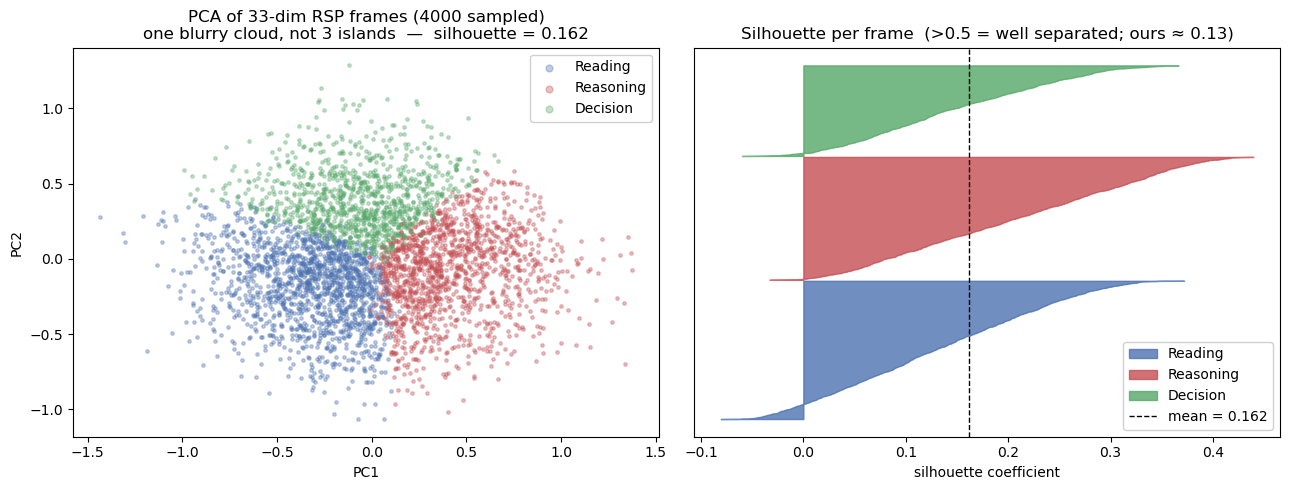

silhouette (K=3) = 0.162  ->  clusters heavily overlap (rule of thumb: <0.25 = no substantial 3-cluster structure)


In [5]:
# Cluster-validity visual: are there really 3 separated clusters, or is K=3 a cut
# through one blurry cloud? Uses the committed partition from section 2.
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

rng = np.random.default_rng(0)
idx = rng.choice(len(X3), 4000, replace=False)        # subsample for a tractable plot
Xs, ls = X3[idx], labels3[idx]
sil = silhouette_score(Xs, ls)                          # ~0.13 = clusters overlap
pcs = PCA(n_components=2).fit_transform(Xs)
state_of = np.array([names3[l] for l in ls])
colors = {"Reading": "#4C72B0", "Reasoning": "#C44E52", "Decision": "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) 2-D PCA scatter coloured by assigned state
for s in STATES:
    m = state_of == s
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.35, c=colors[s], label=s)
axes[0].set_title(f"PCA of 33-dim RSP frames (4000 sampled)\n"
                  f"one blurry cloud, not 3 islands  —  silhouette = {sil:.3f}")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].legend(markerscale=2, framealpha=0.9)

# (b) silhouette plot: per-frame silhouette, grouped/sorted within each cluster
sv = silhouette_samples(Xs, ls)
inv = {v: k for k, v in names3.items()}                 # state name -> cluster id
y = 10
for s in STATES:
    vals = np.sort(sv[ls == inv[s]])
    axes[1].fill_betweenx(np.arange(y, y + len(vals)), 0, vals,
                          color=colors[s], alpha=0.8, label=s)
    y += len(vals) + 10
axes[1].axvline(sil, color="k", ls="--", lw=1, label=f"mean = {sil:.3f}")
axes[1].set_title("Silhouette per frame  (>0.5 = well separated; ours ≈ 0.13)")
axes[1].set_xlabel("silhouette coefficient"); axes[1].set_yticks([])
axes[1].legend(loc="lower right", framealpha=0.9)
plt.tight_layout(); plt.show()

print(f"silhouette (K=3) = {sil:.3f}  ->  clusters heavily overlap "
      f"(rule of thumb: <0.25 = no substantial 3-cluster structure)")

## 3. Spectral power per state (Deliverable #1)

Mean relative spectral power (theta/alpha/beta) of each cognitive state —
averaged over all channels and frames. Loaded from
`outputs/tables/spectral_power.csv`, which the pipeline produced.

           theta  alpha   beta
state                         
Reading    0.395  0.235  0.370
Reasoning  0.578  0.174  0.248
Decision   0.454  0.206  0.340


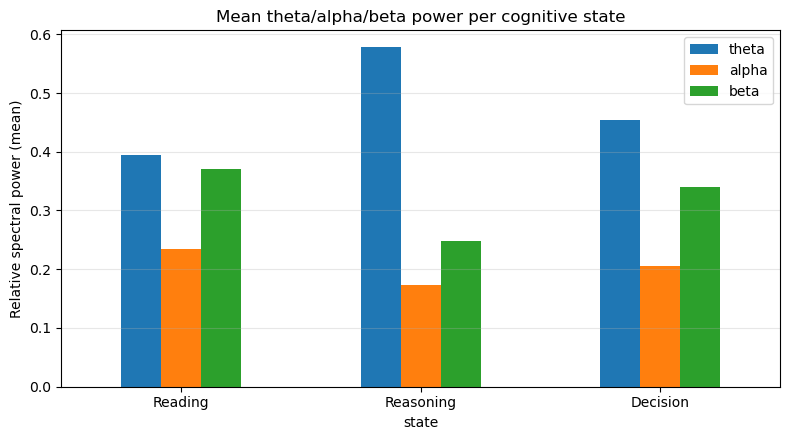

In [6]:
sp_path = config.TABLE_DIR / "spectral_power.csv"
sp = pd.read_csv(sp_path)
# weight by the number of frames -> state-level mean
band_cols = ["theta", "alpha", "beta"]
agg = (sp.assign(**{b: sp[b] * sp["n_frames"] for b in band_cols})
         .groupby("state")[band_cols + ["n_frames"]].sum())
for b in band_cols:
    agg[b] /= agg["n_frames"]
agg = agg.loc[[s for s in STATES if s in agg.index], band_cols]
print(agg.round(3).to_string())

ax = agg.plot(kind="bar", figsize=(8, 4.5), rot=0)
ax.set_ylabel("Relative spectral power (mean)")
ax.set_title("Mean theta/alpha/beta power per cognitive state")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 4. Layer 2 — predict correct/incorrect answering (eqs. 8-9) + cross-validation

Using the professor's labels (`label_answer_data/`), build **9 per-question
logistic models** (features = the 3 SRI ratios, standardised), with per-question
StratifiedKFold, then sum the 9 predictions per subject -> predicted total score
vs the true score.

**Layer-2 training features = exactly the 3 cognitive-state ratios** (paper
eq.6). Two feature sets are compared on the same rows:
- **Our SRI** (tests our Layer-1 end-to-end)
- **the professor's f1/f2/f3** (the reference that reproduces the paper)

In [7]:
lab = load_labels()
m = sri3.merge(lab, on=["subject", "q"], how="inner")
assert not m.duplicated(["subject", "q"]).any(), "merge fan-out"
print(f"merged: {len(m)} rows, {m.subject.nunique()} subjects, {m.q.nunique()} questions "
      f"(balance correct/incorrect = {int((m.label==1).sum())}/{int((m.label==0).sum())})\n")

res_sri_log  = _per_question(m, STATES,            "OUR SRI (logistic)")
res_prof_log = _per_question(m, ["f1","f2","f3"],  "Professor f1/f2/f3 (logistic)")

merged: 198 rows, 22 subjects, 9 questions (balance correct/incorrect = 103/95)


[OUR SRI (logistic)]
  per-Q accuracy: Q1=0.500 Q2=0.545 Q3=0.591 Q4=0.636 Q5=0.545 Q6=0.273 Q7=0.636 Q8=0.591 Q9=0.682
  mean per-Q accuracy = 0.556   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.153  MAE = 1.818   (thesis test: r~0.74, MAE~1.0)

[Professor f1/f2/f3 (logistic)]
  per-Q accuracy: Q1=0.955 Q2=0.682 Q3=0.864 Q4=0.636 Q5=0.727 Q6=0.818 Q7=0.773 Q8=0.818 Q9=0.818
  mean per-Q accuracy = 0.788   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.741  MAE = 1.091   (thesis test: r~0.74, MAE~1.0)


### Graph: per-question accuracy (vs the paper's Table 2)

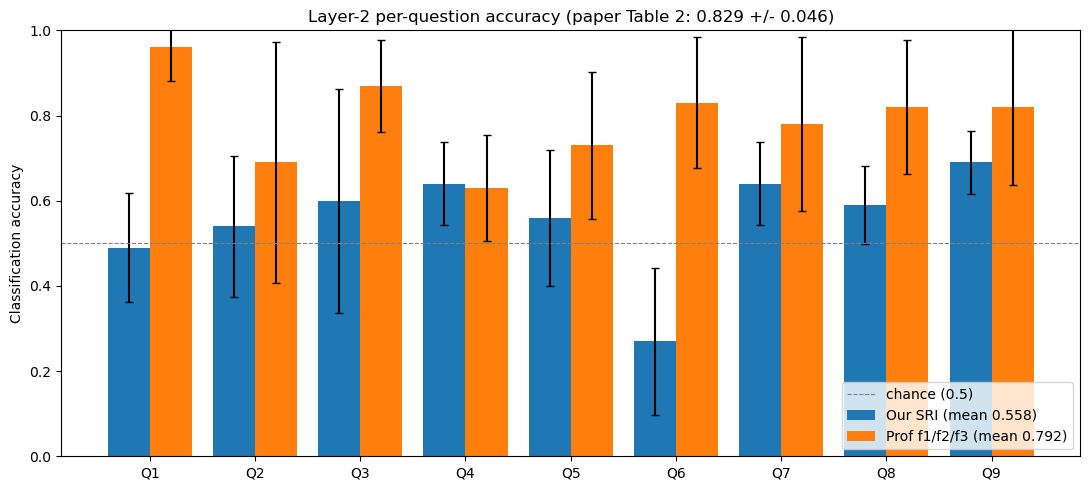

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from classify import N_SPLITS, SEED

def per_q_acc(m, cols):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    qs, mu, sd = [], [], []
    for q, g in m.groupby("q"):
        y = g.label.values
        k = min(N_SPLITS, int(np.bincount(y).min()))
        sc = cross_val_score(clf, g[cols].values, y, scoring="accuracy",
                             cv=StratifiedKFold(k, shuffle=True, random_state=SEED))
        qs.append(q); mu.append(sc.mean()); sd.append(sc.std())
    return np.array(qs), np.array(mu), np.array(sd)

qs, mu_s, sd_s = per_q_acc(m, STATES)
qs, mu_p, sd_p = per_q_acc(m, ["f1","f2","f3"])

w = 0.4; x = np.arange(len(qs))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x-w/2, mu_s, w, yerr=sd_s, capsize=3,
       label=f"Our SRI (mean {mu_s.mean():.3f})")
ax.bar(x+w/2, mu_p, w, yerr=sd_p, capsize=3,
       label=f"Prof f1/f2/f3 (mean {mu_p.mean():.3f})")
ax.axhline(0.5, ls="--", lw=0.8, color="grey", label="chance (0.5)")
ax.set_xticks(x); ax.set_xticklabels([f"Q{q}" for q in qs])
ax.set_ylim(0, 1); ax.set_ylabel("Classification accuracy")
ax.set_title("Layer-2 per-question accuracy (paper Table 2: 0.829 +/- 0.046)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 5. Experiment 1 — upgrade the classifier to SVM-RBF

Question: does switching from logistic to **SVM-RBF** help? Keep the entire
Layer-2 protocol, change only the classifier, on both feature sets / same rows.

In [9]:
log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=0))

rows = []
for clf_name, clf in [("logistic", log), ("svm_rbf", svm)]:
    for feat_name, cols in [("our_sri", STATES), ("prof_f1f2f3", ["f1","f2","f3"])]:
        r = _per_question(m, cols, f"{clf_name} | {feat_name}", clf=clf)
        rows.append({"classifier": clf_name, "features": feat_name,
                     "mean_acc": r["mean_acc"], "score_r": r["score_r"],
                     "score_mae": r["score_mae"]})
exp1 = pd.DataFrame(rows)
print("\n=== Experiment 1 summary ===")
print(exp1.to_string(index=False))


[logistic | our_sri]
  per-Q accuracy: Q1=0.500 Q2=0.545 Q3=0.591 Q4=0.636 Q5=0.545 Q6=0.273 Q7=0.636 Q8=0.591 Q9=0.682
  mean per-Q accuracy = 0.556   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.153  MAE = 1.818   (thesis test: r~0.74, MAE~1.0)

[logistic | prof_f1f2f3]
  per-Q accuracy: Q1=0.955 Q2=0.682 Q3=0.864 Q4=0.636 Q5=0.727 Q6=0.818 Q7=0.773 Q8=0.818 Q9=0.818
  mean per-Q accuracy = 0.788   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.741  MAE = 1.091   (thesis test: r~0.74, MAE~1.0)

[svm_rbf | our_sri]
  per-Q accuracy: Q1=0.545 Q2=0.545 Q3=0.591 Q4=0.591 Q5=0.409 Q6=0.273 Q7=0.727 Q8=0.591 Q9=0.727
  mean per-Q accuracy = 0.556   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.093  MAE = 1.909   (thesis test: r~0.74, MAE~1.0)

[svm_rbf | prof_f1f2f3]
  per-Q accuracy: Q1=0.955 Q2=0.955 Q3=0.955 Q4=0.727 Q5=0.773 Q6=0.864 Q7=0.727 Q8=0.773 Q9=0.773
  mean per-Q accuracy = 0.833   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.

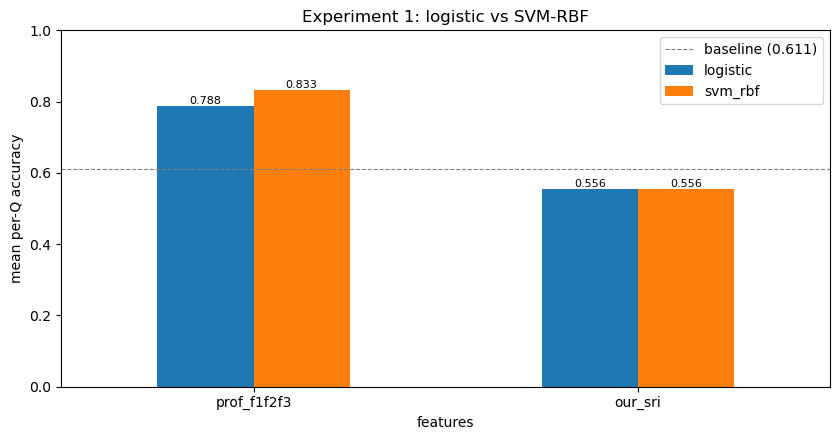

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
piv = exp1.pivot(index="features", columns="classifier", values="mean_acc")
piv = piv.loc[["prof_f1f2f3", "our_sri"]]
piv.plot(kind="bar", ax=ax, rot=0)
ax.axhline(0.611, ls="--", lw=0.8, color="grey", label="baseline (0.611)")
ax.set_ylabel("mean per-Q accuracy"); ax.set_ylim(0, 1)
ax.set_title("Experiment 1: logistic vs SVM-RBF")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

**Reading the result:** on the professor's f1/f2/f3, SVM-RBF clearly beats
logistic (~0.833 vs 0.788, close to the paper's 0.829) -> a real Layer-2 upgrade
to propose. **But** on our SRI, SVM does not rescue it (~0.56) -> confirms the
problem is in the **feature (Layer-1), not the model**.

### Graph: per-question accuracy with SVM-RBF

Experiment 1 above compared the *mean* accuracy; this breaks it down **per
question** using the winning classifier (SVM-RBF) — the same view as the
logistic per-question chart in section 4, on both feature sets / same rows.

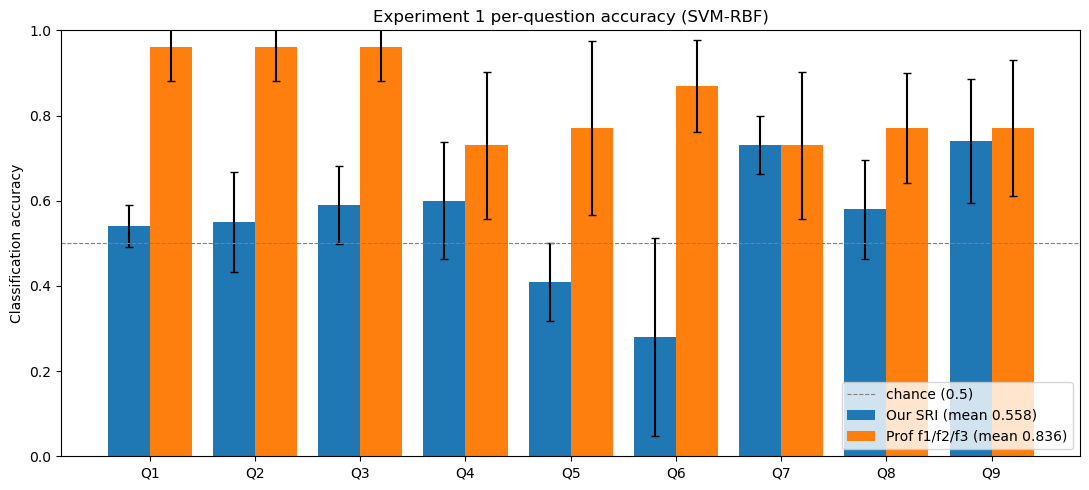

In [11]:
# per-question accuracy under SVM-RBF (cf. the logistic per-Q chart in section 4)
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=0))

def per_q_acc_clf(m, cols, clf):
    qs, mu, sd = [], [], []
    for q, g in m.groupby("q"):
        y = g.label.values
        k = min(N_SPLITS, int(np.bincount(y).min()))
        sc = cross_val_score(clf, g[cols].values, y, scoring="accuracy",
                             cv=StratifiedKFold(k, shuffle=True, random_state=SEED))
        qs.append(q); mu.append(sc.mean()); sd.append(sc.std())
    return np.array(qs), np.array(mu), np.array(sd)

qs, mu_s, sd_s = per_q_acc_clf(m, STATES, svm)
qs, mu_p, sd_p = per_q_acc_clf(m, ["f1", "f2", "f3"], svm)

w = 0.4; x = np.arange(len(qs))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x-w/2, mu_s, w, yerr=sd_s, capsize=3,
       label=f"Our SRI (mean {mu_s.mean():.3f})")
ax.bar(x+w/2, mu_p, w, yerr=sd_p, capsize=3,
       label=f"Prof f1/f2/f3 (mean {mu_p.mean():.3f})")
ax.axhline(0.5, ls="--", lw=0.8, color="grey", label="chance (0.5)")
ax.set_xticks(x); ax.set_xticklabels([f"Q{q}" for q in qs])
ax.set_ylim(0, 1); ax.set_ylabel("Classification accuracy")
ax.set_title("Experiment 1 per-question accuracy (SVM-RBF)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 6. Experiment 2 — 4th-order band-pass filter (per the thesis)

The thesis specifies a Butterworth **4th-order (四階)** filter, while the code +
IEEE paper use 3rd-order. This is the last untested lever. We set
`config.FILTER_ORDER = 4`, re-run the full Layer-1 -> new SRI -> new Layer-2, and
compare with the baseline.

> Takes a moment (re-runs Layer-1 again).

In [12]:
config.FILTER_ORDER = 4
print("set config.FILTER_ORDER =", config.FILTER_ORDER, "and re-running Layer-1...\n")
X4, groups4, labels4, names4 = M.cluster_frames()
sri4 = M.compute_sri(labels4, groups4, names4)

m4 = sri4.merge(lab, on=["subject", "q"], how="inner")
assert not m4.duplicated(["subject", "q"]).any(), "merge fan-out"
print(f"\nmerged (4th-order): {len(m4)} rows, {m4.subject.nunique()} subjects\n")
res_sri4  = _per_question(m4, STATES,           "OUR SRI (4th-order)")
res_prof4 = _per_question(m4, ["f1","f2","f3"], "Prof f1/f2/f3 (4th-order rows)")

config.FILTER_ORDER = 3  # restore the baseline
print("\nrestored config.FILTER_ORDER =", config.FILTER_ORDER)

set config.FILTER_ORDER = 4 and re-running Layer-1...

complete subjects (Q1-Q9, files): 27
still complete after artifact rejection: 22
dropped (a question emptied by rejection): ['S2', 'S16', 'S18', 'S25', 'S27']
  ['S1', 'S3', 'S4', 'S5', 'S6', 'S7', 'S10', 'S11', 'S12', 'S13', 'S14', 'S19', 'S22', 'S24', 'S26', 'S28', 'S29', 'S30', 'S31', 'S34', 'S37', 'S38']
feature matrix: (49675, 33)  frames=49675
cluster -> state: {1: 'Reading', 0: 'Decision', 2: 'Reasoning'}

merged (4th-order): 198 rows, 22 subjects


[OUR SRI (4th-order)]
  per-Q accuracy: Q1=0.545 Q2=0.500 Q3=0.545 Q4=0.591 Q5=0.591 Q6=0.364 Q7=0.682 Q8=0.545 Q9=0.727
  mean per-Q accuracy = 0.566   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.206  MAE = 1.727   (thesis test: r~0.74, MAE~1.0)

[Prof f1/f2/f3 (4th-order rows)]
  per-Q accuracy: Q1=0.955 Q2=0.682 Q3=0.864 Q4=0.636 Q5=0.727 Q6=0.818 Q7=0.773 Q8=0.818 Q9=0.818
  mean per-Q accuracy = 0.788   (paper Table 2: 0.725-0.875)
  score-level: Pearson r = 0.

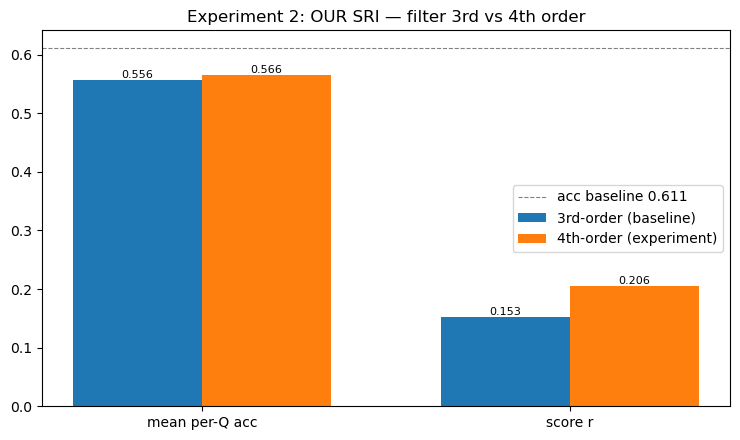

OUR SRI 3rd-order : acc 0.556  r 0.153
OUR SRI 4th-order : acc 0.566  r 0.206
control f1/f2/f3  : 3rd 0.788 | 4th 0.788


In [13]:
# compare OUR SRI: 3rd-order vs 4th-order
labels_ = ["mean_acc", "score_r"]
order3 = [res_sri_log["mean_acc"], res_sri_log["score_r"]]
order4 = [res_sri4["mean_acc"],   res_sri4["score_r"]]

x = np.arange(len(labels_)); w = 0.35
fig, ax = plt.subplots(figsize=(7.5, 4.5))
b1 = ax.bar(x-w/2, order3, w, label="3rd-order (baseline)")
b2 = ax.bar(x+w/2, order4, w, label="4th-order (experiment)")
ax.axhline(0.611, ls="--", lw=0.8, color="grey", label="acc baseline 0.611")
ax.set_xticks(x); ax.set_xticklabels(["mean per-Q acc", "score r"])
ax.set_title("Experiment 2: OUR SRI — filter 3rd vs 4th order")
for b in (b1, b2): ax.bar_label(b, fmt="%.3f", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

print(f"OUR SRI 3rd-order : acc {res_sri_log['mean_acc']:.3f}  r {res_sri_log['score_r']:.3f}")
print(f"OUR SRI 4th-order : acc {res_sri4['mean_acc']:.3f}  r {res_sri4['score_r']:.3f}")
print(f"control f1/f2/f3  : 3rd {res_prof_log['mean_acc']:.3f} | 4th {res_prof4['mean_acc']:.3f}")

**Reading the result:** check whether the 4th-order SRI moves toward ~0.79
and whether score r rises clearly. If it does not move, then filter order is
**not** the Layer-1 fix (see the actual numbers above). The f1/f2/f3 is the
control — if it stays flat, the change comes from our partition, not from a
different row set.

## 7. SRI by student achievement group — baseline vs experiment

Paper-style figure ("Proportion Distribution of Three Cognitive States Across
Questions"): split subjects into two achievement groups by their **total
answer-correctness score** (sum of the 9 labels; median = 5):
- **High-Achieving** (Top Group): score >= 6
- **Average-Achieving** (Middle Group): score <= 5

Each Q1-Q9 panel shows the mean SRI (%) of the 3 states for the two groups
(error bars = between-subject std). We draw it twice to **compare the model
(baseline 3rd-order SRI) against the experiment (4th-order SRI)** — i.e. whether
the 4th-order filter changes how the two student groups distribute their
cognitive states.

SRI by group - BASELINE (3rd-order filter): High(score>=6)=10 subj  Average=12 subj


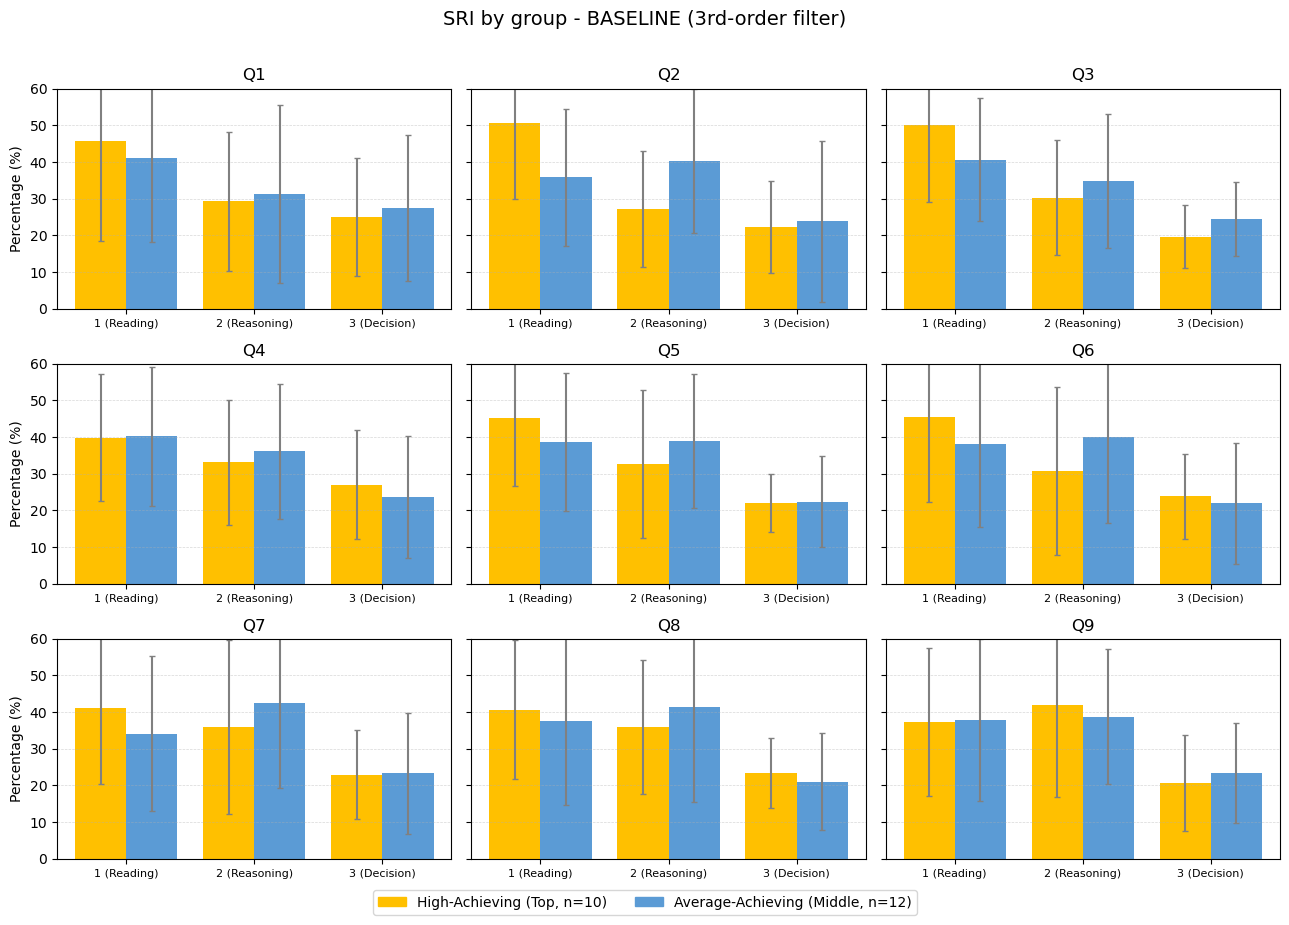

In [14]:
from matplotlib.patches import Patch

HIGH_COLOR, AVG_COLOR = "#FFC000", "#5B9BD5"   # gold = Top, blue = Middle
SCORE_CUT = 6                                  # High = total score >= 6
STATE_TICKS = ["1 (Reading)", "2 (Reasoning)", "3 (Decision)"]

def plot_by_group(sri_df, labels_df, title):
    mg = sri_df.merge(labels_df[["subject", "q", "label"]],
                      on=["subject", "q"], how="inner").copy()
    assert not mg.duplicated(["subject", "q"]).any(), "merge fan-out"
    score = mg.groupby("subject").label.sum()        # total score per subject
    high = set(score[score >= SCORE_CUT].index)
    mg["group"] = np.where(mg.subject.isin(high), "High", "Average")
    mg[STATES] = mg[STATES] * 100                     # proportions -> percent
    n_high, n_avg = len(high), score.size - len(high)
    print(f"{title}: High(score>={SCORE_CUT})={n_high} subj  Average={n_avg} subj")

    x = np.arange(len(STATES)); width = 0.4
    fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharey=True)
    for ax, q in zip(axes.flat, range(1, 10)):
        sub = mg[mg.q == q]
        hi = sub[sub.group == "High"][STATES]
        av = sub[sub.group == "Average"][STATES]
        ax.bar(x - width/2, hi.mean().values, width, yerr=hi.std().values,
               capsize=2, ecolor="grey", color=HIGH_COLOR)
        ax.bar(x + width/2, av.mean().values, width, yerr=av.std().values,
               capsize=2, ecolor="grey", color=AVG_COLOR)
        ax.set_title(f"Q{q}"); ax.set_xticks(x)
        ax.set_xticklabels(STATE_TICKS, fontsize=8)
        ax.set_ylim(0, 60); ax.grid(axis="y", ls="--", lw=0.5, alpha=0.5)
    for ax in axes[:, 0]:
        ax.set_ylabel("Percentage (%)")
    fig.suptitle(title, fontsize=14)
    handles = [Patch(color=HIGH_COLOR, label=f"High-Achieving (Top, n={n_high})"),
               Patch(color=AVG_COLOR, label=f"Average-Achieving (Middle, n={n_avg})")]
    fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.02))
    fig.tight_layout(rect=[0, 0.05, 1, 0.97]); plt.show()

# baseline = the model the paper uses (3rd-order SRI)
plot_by_group(sri3, lab, "SRI by group - BASELINE (3rd-order filter)")

SRI by group - EXPERIMENT (4th-order filter): High(score>=6)=10 subj  Average=12 subj


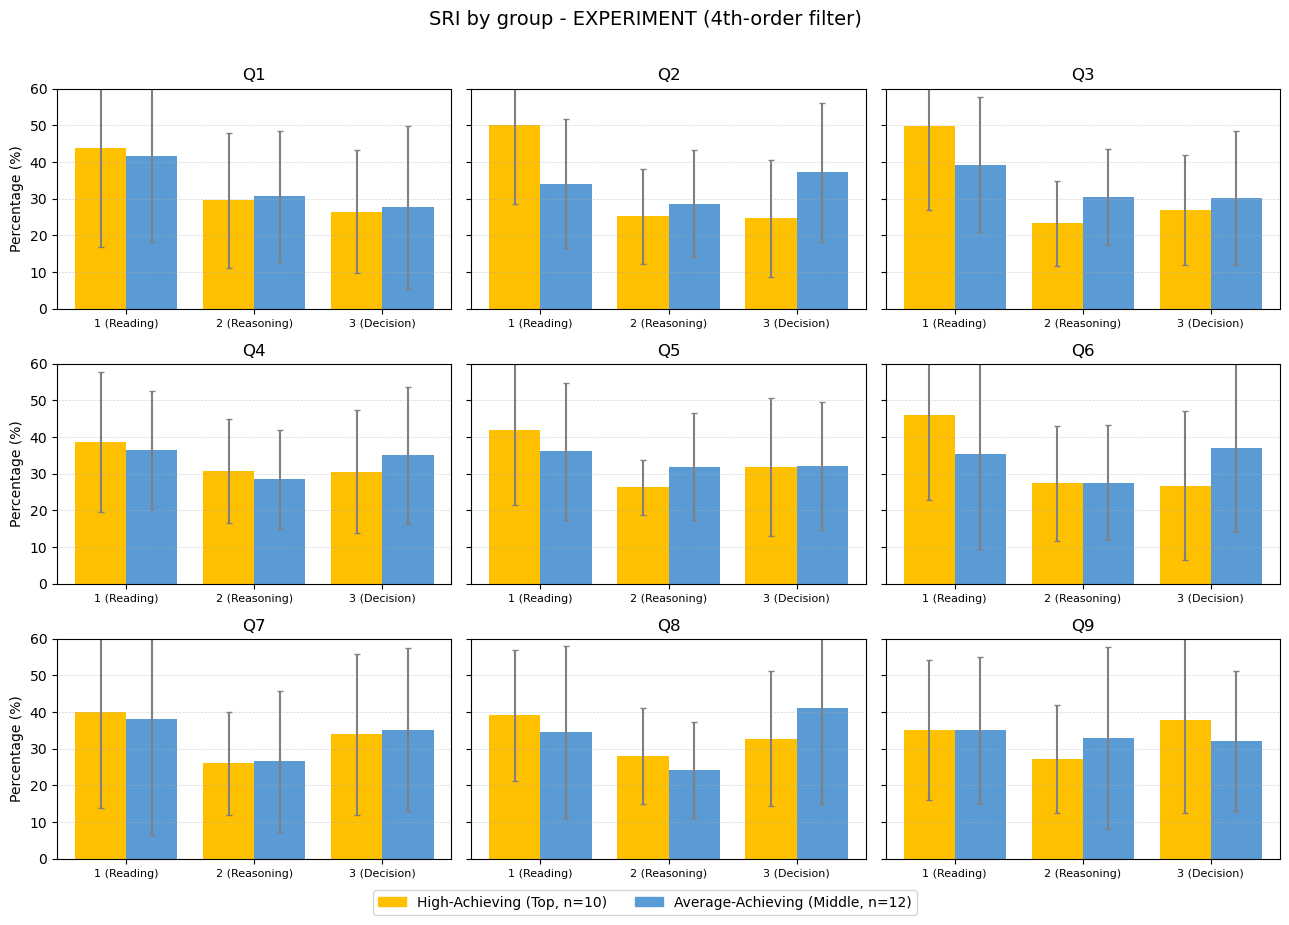

In [15]:
# experiment = the 4th-order filter SRI computed in section 6
plot_by_group(sri4, lab, "SRI by group - EXPERIMENT (4th-order filter)")

## 8. Summary

| What was tested | Result | Meaning |
|---|---|---|
| **Exp 1: SVM-RBF** | f1/f2/f3 rises to ~0.833 (from 0.788); our SRI still ~0.56 | a real Layer-2 upgrade, but does not fix Layer-1 |
| **Exp 2: 4th-order filter** | see the actual numbers above | tests the last Layer-1 lever |
| **SRI by group** | High vs Average students, baseline vs 4th-order | the two groups barely separate (consistent with the weak Layer-1 partition) |

**Overall:** the classification system (Layer 2) is correct and reproduces the
paper — SVM-RBF makes it even better. The remaining gap is entirely in the
**fidelity of the Layer-1 partition**, which cannot be fixed by more code; it
needs the professor's real seed / preprocessing / per-(subject, question) state
assignments.

**Recommendation:** adopt SVM-RBF as the proposed Layer-2 model, and bring the
Exp 2 result to the next meeting with the professor.